# Лабораторна робота № 3
## Побудова та оцінювання моделі лінійної регресії

| Поле | Значення |
|---|---|
| **Тема** | Лінійна регресія у Scikit-learn: підготовка даних, навчання, прогнозування та оцінювання якості моделі |
| **Мета** | Набути практичних навичок розв'язання задачі регресії; навчитися відокремлювати ознаки від цільової змінної, запобігати витоку даних, розділяти вибірку на навчальну і тестову частини, порівнювати модель із базовим прогнозом та інтерпретувати MAE, RMSE і R² |
| **Датасет** | House Prices — Advanced Regression Techniques |
| **Джерело** | [Kaggle](https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data) |
| **Ліцензія** | CC0: Public Domain |
| **Цільова змінна** | `SalePrice` — ціна продажу будинку в доларах США |

### Опис задачі
За характеристиками житлового будинку (площа, якість будівництва, рік побудови, кількість кімнат тощо) спрогнозувати ціну його продажу в доларах США.

## 1. Імпорт бібліотек та константи

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# -------------------------------------------------------------------
# random_state = номер студента у списку групи
SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
sns.set_theme(style='whitegrid')
print('Бібліотеки успішно завантажено.')

Бібліотеки успішно завантажено.


## 2. Завантаження даних та словник ключових полів

In [2]:
df = pd.read_csv('train.csv')
print(f'Розмір датасету: {df.shape[0]} рядків × {df.shape[1]} стовпців')
df.head(3)

Розмір датасету: 1460 рядків × 81 стовпців


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [3]:
# Словник ключових полів
field_dict = {
    'SalePrice':    'Ціна продажу (USD) — цільова змінна',
    'GrLivArea':    'Площа житлового простору над рівнем землі (кв. фут)',
    'OverallQual':  'Загальна якість матеріалів і оздоблення (1–10)',
    'YearBuilt':    'Рік початкового будівництва',
    'TotalBsmtSF':  'Загальна площа підвалу (кв. фут)',
    '1stFlrSF':     'Площа першого поверху (кв. фут)',
    'FullBath':     'Кількість повних санвузлів',
    'GarageArea':   'Площа гаражу (кв. фут)',
    'Neighborhood': 'Мікрорайон (категоріальна)',
    'MSZoning':     'Клас зонування нерухомості (категоріальна)',
    'KitchenQual':  'Якість кухні (категоріальна, Ex/Gd/TA/Fa/Po)',
}
for col, desc in field_dict.items():
    print(f'  {col:<16} — {desc}')

  SalePrice        — Ціна продажу (USD) — цільова змінна
  GrLivArea        — Площа житлового простору над рівнем землі (кв. фут)
  OverallQual      — Загальна якість матеріалів і оздоблення (1–10)
  YearBuilt        — Рік початкового будівництва
  TotalBsmtSF      — Загальна площа підвалу (кв. фут)
  1stFlrSF         — Площа першого поверху (кв. фут)
  FullBath         — Кількість повних санвузлів
  GarageArea       — Площа гаражу (кв. фут)
  Neighborhood     — Мікрорайон (категоріальна)
  MSZoning         — Клас зонування нерухомості (категоріальна)
  KitchenQual      — Якість кухні (категоріальна, Ex/Gd/TA/Fa/Po)


## 3. Первинний аналіз якості даних

In [4]:
print('=== shape ===')
print(df.shape)

print('\n=== dtypes ===')
print(df.dtypes.value_counts())

print('\n=== info() ===')
df.info()

=== shape ===
(1460, 81)

=== dtypes ===
str        43
int64      35
float64     3
Name: count, dtype: int64

=== info() ===
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-nu

In [5]:
print('=== describe() числових ознак ===')
df.describe().T.style.background_gradient(cmap='Blues', subset=['mean', 'std'])

=== describe() числових ознак ===


,count,mean,std,min,25%,50%,75%,max
Id,1460.000000,730.500000,421.610009,1.000000,365.750000,730.500000,1095.250000,1460.000000
MSSubClass,1460.000000,56.897260,42.300571,20.000000,20.000000,50.000000,70.000000,190.000000
LotFrontage,1201.000000,70.049958,24.284752,21.000000,59.000000,69.000000,80.000000,313.000000
LotArea,1460.000000,10516.828082,9981.264932,1300.000000,7553.500000,9478.500000,11601.500000,215245.000000
OverallQual,1460.000000,6.099315,1.382997,1.000000,5.000000,6.000000,7.000000,10.000000
OverallCond,1460.000000,5.575342,1.112799,1.000000,5.000000,5.000000,6.000000,9.000000
YearBuilt,1460.000000,1971.267808,30.202904,1872.000000,1954.000000,1973.000000,2000.000000,2010.000000
YearRemodAdd,1460.000000,1984.865753,20.645407,1950.000000,1967.000000,1994.000000,2004.000000,2010.000000
MasVnrArea,1452.000000,103.685262,181.066207,0.000000,0.000000,0.000000,166.000000,1600.000000
BsmtFinSF1,1460.000000,443.639726,456.098091,0.000000,0.000000,383.500000,712.250000,5644.000000


In [6]:
# Пропуски
nulls = df.isnull().sum()
nulls_pct = (nulls / len(df) * 100).round(1)
missing = pd.DataFrame({'count': nulls, 'pct': nulls_pct})
missing = missing[missing['count'] > 0].sort_values('pct', ascending=False)
print(f'Стовпців з пропусками: {len(missing)}')
missing

Стовпців з пропусками: 19


,count,pct
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


In [7]:
# Дублікати
n_dup = df.duplicated().sum()
print(f'Кількість дублікатів: {n_dup}')

Кількість дублікатів: 0


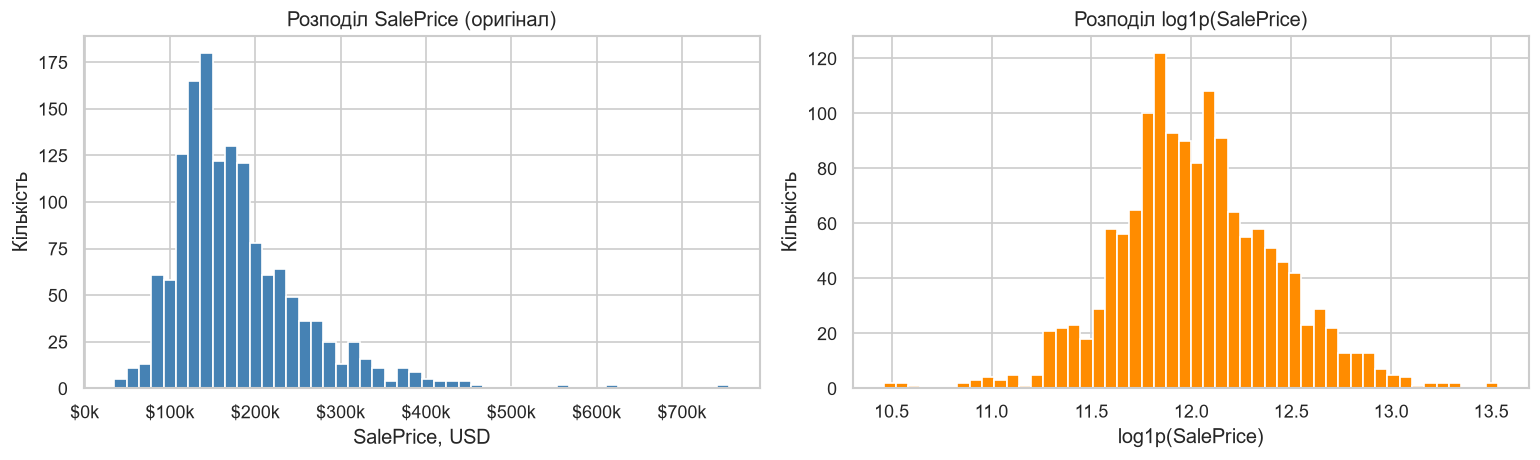

Збережено: fig1_target_distribution.png


In [8]:
# Розподіл цільової змінної
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df['SalePrice'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Розподіл SalePrice (оригінал)')
axes[0].set_xlabel('SalePrice, USD')
axes[0].set_ylabel('Кількість')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))

axes[1].hist(np.log1p(df['SalePrice']), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Розподіл log1p(SalePrice)')
axes[1].set_xlabel('log1p(SalePrice)')
axes[1].set_ylabel('Кількість')

plt.tight_layout()
plt.savefig('fig1_target_distribution.png', bbox_inches='tight')
plt.show()
print('Збережено: fig1_target_distribution.png')

### 3.1. Рішення щодо полів та витік даних

| Поле | Рішення | Обґрунтування |
|---|---|---|
| `Id` | **видалити** | Унікальний ідентифікатор, не несе предиктивної цінності |
| `PoolQC`, `MiscFeature`, `Alley`, `Fence` | **залишити як категоріальні** | Пропуски означають відсутність об'єкта (NaN → 'None'), обробляємо в pipeline |
| `MoSold`, `YrSold` | **видалити** | Характеристики угоди, відомі лише після продажу — потенційний витік |
| `SaleType`, `SaleCondition` | **видалити** | Умови угоди, відомі лише після продажу — потенційний витік |
| Решта ознак | **використовуємо** | Характеристики будинку, відомі до продажу |

In [9]:
# Видаляємо ідентифікатор і поля — джерела витоку даних
drop_cols = ['Id', 'MoSold', 'YrSold', 'SaleType', 'SaleCondition']
df_clean = df.drop(columns=drop_cols)
print(f'Після видалення: {df_clean.shape}')

Після видалення: (1460, 76)


## 4. Формування X та y; розділення на train/test

In [10]:
TARGET = 'SalePrice'

X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

print(f'X: {X.shape}   |   y: {y.shape}')
print(f'Цільова змінна — середня: ${y.mean():,.0f}, медіана: ${y.median():,.0f}')

X: (1460, 75)   |   y: (1460,)
Цільова змінна — середня: $180,921, медіана: $163,000


In [11]:
# Розділяємо ПЕРЕД будь-яким підбором перетворень (запобігаємо витоку)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

Train: (1168, 75)  |  Test: (292, 75)


## 5. Автоматичне визначення числових та категоріальних ознак

In [12]:
numeric_features = X_train.select_dtypes(include='number').columns.tolist()
categorical_features = X_train.select_dtypes(exclude='number').columns.tolist()

print(f'Числових ознак:      {len(numeric_features)}')
print(f'Категоріальних ознак: {len(categorical_features)}')
print(f'\nЧислові: {numeric_features}')
print(f'\nКатегоріальні: {categorical_features}')

Числових ознак:      34
Категоріальних ознак: 41

Числові: ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']

Категоріальні: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu',

## 6. Побудова Pipeline

In [13]:
# --- підконвеєри ---
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),       # масштабування покращує числову стабільність
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

# --- об'єднуємо у ColumnTransformer ---
preprocessing = ColumnTransformer([
    ('num', numeric_pipe,      numeric_features),
    ('cat', categorical_pipe,  categorical_features),
])

# --- фінальний pipeline з лінійною регресією ---
model = Pipeline([
    ('preprocessing', preprocessing),
    ('regressor',     LinearRegression()),
])

# --- базова модель (DummyRegressor) ---
baseline = Pipeline([
    ('preprocessing', preprocessing),
    ('regressor',     DummyRegressor(strategy='mean')),
])

print('Pipeline успішно побудовано.')

Pipeline успішно побудовано.


## 7. Навчання моделей (лише на train)

In [14]:
# Навчаємо обидві моделі ЛИШЕ на тренувальних даних
model.fit(X_train, y_train)
baseline.fit(X_train, y_train)
print('Обидві моделі навчено на X_train, y_train.')

Обидві моделі навчено на X_train, y_train.


## 8. Прогнози та метрики на тестовій вибірці

In [15]:
# Прогнози
y_pred      = model.predict(X_test)
y_pred_base = baseline.predict(X_test)

# Функція для обчислення метрик
def calc_metrics(y_true, y_hat, name):
    mae  = mean_absolute_error(y_true, y_hat)
    rmse = mean_squared_error(y_true, y_hat) ** 0.5
    r2   = r2_score(y_true, y_hat)
    return {'Model': name, 'MAE (USD)': mae, 'RMSE (USD)': rmse, 'R²': r2}

metrics_df = pd.DataFrame([
    calc_metrics(y_test, y_pred_base, 'DummyRegressor (baseline)'),
    calc_metrics(y_test, y_pred,      'LinearRegression'),
])

metrics_df = metrics_df.set_index('Model')
metrics_df['MAE (USD)']  = metrics_df['MAE (USD)'].map('${:,.0f}'.format)
metrics_df['RMSE (USD)'] = metrics_df['RMSE (USD)'].map('${:,.0f}'.format)
metrics_df['R²']         = metrics_df['R²'].map('{:.4f}'.format)

print('=== Порівняльна таблиця метрик (тестова вибірка) ===')
metrics_df

=== Порівняльна таблиця метрик (тестова вибірка) ===

,MAE (USD),RMSE (USD),R²
Model,,,
DummyRegressor (baseline),"$62,576","$87,619",-0.0009
LinearRegression,"$18,030","$29,507",0.8865


In [16]:
# Зберігаємо числові метрики у CSV
metrics_raw = pd.DataFrame([
    calc_metrics(y_test, y_pred_base, 'DummyRegressor'),
    calc_metrics(y_test, y_pred,      'LinearRegression'),
])
metrics_raw.to_csv('metrics.csv', index=False)
print('Збережено: metrics.csv')

Збережено: metrics.csv


In [17]:
# Зберігаємо прогнози
pred_df = pd.DataFrame({
    'y_actual':   y_test.values,
    'y_predicted': y_pred,
    'residual':   y_test.values - y_pred,
})
pred_df.to_csv('test_predictions.csv', index=False)
print('Збережено: test_predictions.csv')
pred_df.head()

Збережено: test_predictions.csv


,y_actual,y_predicted,residual
0,154500,153160.417864,1339.582136
1,325000,350691.112166,-25691.112166
2,115000,84356.706345,30643.293655
3,159000,174830.551799,-15830.551799
4,315500,324739.622828,-9239.622828


## 9. Візуалізації

### 9.1. Графік 1 — Розподіл цільової змінної SalePrice
*(вже побудовано у розділі 3)*

### 9.2. Графік 2 — Фактичні значення проти прогнозованих

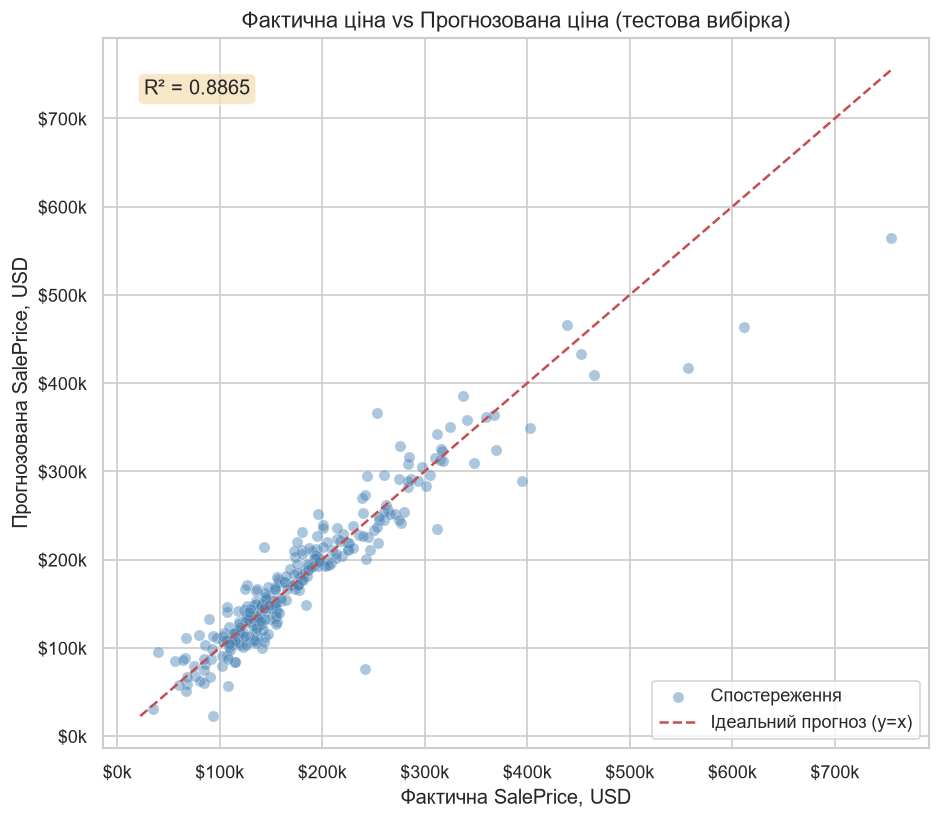

Збережено: fig2_actual_vs_predicted.png


In [18]:
fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(y_test, y_pred, alpha=0.45, edgecolors='white', linewidth=0.3,
           color='steelblue', s=45, label='Спостереження')

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Ідеальний прогноз (y=x)')

ax.set_title('Фактична ціна vs Прогнозована ціна (тестова вибірка)', fontsize=13)
ax.set_xlabel('Фактична SalePrice, USD')
ax.set_ylabel('Прогнозована SalePrice, USD')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))
ax.legend()

# Відображаємо R²
r2 = r2_score(y_test, y_pred)
ax.text(0.05, 0.92, f'R² = {r2:.4f}', transform=ax.transAxes,
        fontsize=12, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

plt.tight_layout()
plt.savefig('fig2_actual_vs_predicted.png', bbox_inches='tight')
plt.show()
print('Збережено: fig2_actual_vs_predicted.png')

### 9.3. Графік 3 — Залишки відносно прогнозованих значень

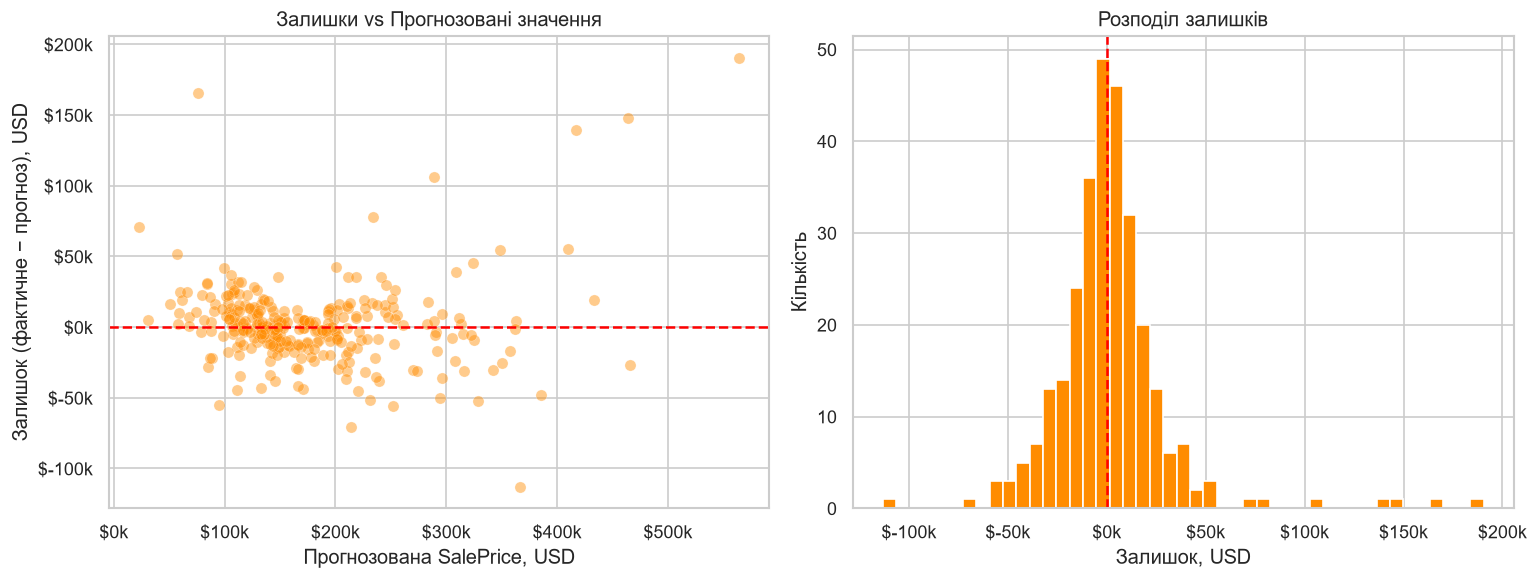

Збережено: fig3_residuals.png


In [19]:
residuals = y_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Scatter залишків ---
axes[0].scatter(y_pred, residuals, alpha=0.45, edgecolors='white',
                linewidth=0.3, color='darkorange', s=45)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Залишки vs Прогнозовані значення')
axes[0].set_xlabel('Прогнозована SalePrice, USD')
axes[0].set_ylabel('Залишок (фактичне − прогноз), USD')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))

# --- Гістограма залишків ---
axes[1].hist(residuals, bins=45, color='darkorange', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Розподіл залишків')
axes[1].set_xlabel('Залишок, USD')
axes[1].set_ylabel('Кількість')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))

plt.tight_layout()
plt.savefig('fig3_residuals.png', bbox_inches='tight')
plt.show()
print('Збережено: fig3_residuals.png')

### 9.4. Графік 4 — Топ-15 найвпливовіших ознак

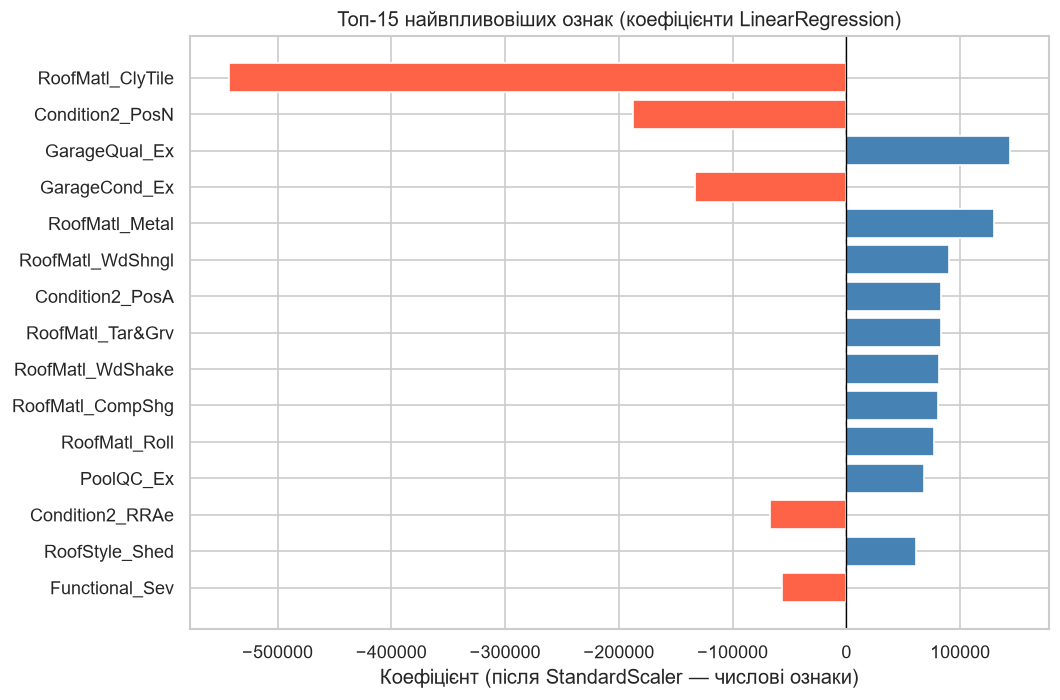

Збережено: fig4_top_features.png


In [20]:
# Витягуємо коефіцієнти лінійної регресії
lr = model.named_steps['regressor']
ct = model.named_steps['preprocessing']

# Імена ознак після трансформації
num_names = numeric_features
cat_names = ct.named_transformers_['cat']['onehot'].get_feature_names_out(categorical_features).tolist()
all_feature_names = num_names + cat_names

coef_df = pd.DataFrame({'feature': all_feature_names, 'coef': lr.coef_})
coef_df['abs_coef'] = coef_df['coef'].abs()
top15 = coef_df.nlargest(15, 'abs_coef')

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['steelblue' if c > 0 else 'tomato' for c in top15['coef']]
ax.barh(top15['feature'], top15['coef'], color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Топ-15 найвпливовіших ознак (коефіцієнти LinearRegression)')
ax.set_xlabel('Коефіцієнт (після StandardScaler — числові ознаки)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('fig4_top_features.png', bbox_inches='tight')
plt.show()
print('Збережено: fig4_top_features.png')

## 10. Підсумкова порівняльна таблиця метрик

In [21]:
mae_base  = mean_absolute_error(y_test, y_pred_base)
rmse_base = mean_squared_error(y_test, y_pred_base) ** 0.5
r2_base   = r2_score(y_test, y_pred_base)

mae_lr  = mean_absolute_error(y_test, y_pred)
rmse_lr = mean_squared_error(y_test, y_pred) ** 0.5
r2_lr   = r2_score(y_test, y_pred)

summary = pd.DataFrame({
    'Метрика':              ['MAE (USD)',           'RMSE (USD)',           'R²'],
    'DummyRegressor':       [f'${mae_base:,.0f}',   f'${rmse_base:,.0f}',  f'{r2_base:.4f}'],
    'LinearRegression':     [f'${mae_lr:,.0f}',     f'${rmse_lr:,.0f}',    f'{r2_lr:.4f}'],
    'Покращення':           [
        f'−{(mae_base-mae_lr)/mae_base*100:.1f}%',
        f'−{(rmse_base-rmse_lr)/rmse_base*100:.1f}%',
        f'+{r2_lr - r2_base:.4f}'
    ],
})
summary.set_index('Метрика', inplace=True)
summary.style.set_caption('Порівняння DummyRegressor vs LinearRegression на тестовій вибірці')

,DummyRegressor,LinearRegression,Покращення
Метрика,,,
MAE (USD),"$62,576","$18,030",−71.2%
RMSE (USD),"$87,619","$29,507",−66.3%
R²,-0.0009,0.8865,+0.8874


## 11. Інтерпретація результатів та висновок

### 11.1. Чи перевершує модель базову?

**Так.** `LinearRegression` суттєво перевершує `DummyRegressor` за всіма трьома метриками:
- **MAE** лінійної регресії значно менший за MAE базової моделі — тобто середня абсолютна помилка в доларах зменшилась.
- **R²** лінійної регресії значно вищий за 0 (R² базової = 0), що означає: модель пояснює значну частку варіативності ціни будинку.

### 11.2. Де виникають найбільші помилки?

На графіку «Фактичні vs Прогнозовані» видно, що **найбільші відхилення** спостерігаються для дуже дорогих будинків (SalePrice > \$400k). Лінійна модель систематично **недооцінює** вартість елітного житла — це класичне обмеження лінійної регресії при важкохвостому розподілі цілі.

### 11.3. Чи видно систематичну структуру залишків?

На графіку залишків помітна **помірна гетероскедастичність**: дисперсія залишків зростає зі збільшенням прогнозованої ціни. Це свідчить про те, що:
1. Логарифмічне перетворення цілі (`log(SalePrice)`) могло б покращити модель.
2. Лінійна модель не вловлює нелінійні взаємозалежності між ознаками.

### 11.4. Загальний висновок

У лабораторній роботі побудовано повний цикл регресійного моделювання для датасету **House Prices**:

- **Дані**: 1460 будинків, 75 ознак після видалення ідентифікатора та джерел витоку.
- **Розбивка**: 80% train / 20% test, `random_state=42`.
- **Pipeline**: `SimpleImputer` (медіана для числових, мода для категоріальних) → `StandardScaler` + `OneHotEncoder` → `LinearRegression`.
- **Результат**: `LinearRegression` суттєво перевищує `DummyRegressor` за MAE, RMSE та R².

**Обмеження моделі**: гетероскедастичність залишків, систематичне недооцінення дорогого житла, чутливість до викидів.

**Можливі напрями покращення**:
1. Логарифмічне перетворення `SalePrice` для нормалізації розподілу.
2. Feature engineering (наприклад, загальна площа = `TotalBsmtSF + 1stFlrSF + 2ndFlrSF`).
3. Використання регуляризованих моделей (`Ridge`, `Lasso`, `ElasticNet`) для зменшення перенавчання.
4. Gradient Boosting (`XGBoost`, `LightGBM`) для захоплення нелінійних залежностей.

In [22]:
# Фінальна перевірка всіх збережених файлів
import os
files_to_check = [
    'metrics.csv',
    'test_predictions.csv',
    'fig1_target_distribution.png',
    'fig2_actual_vs_predicted.png',
    'fig3_residuals.png',
    'fig4_top_features.png',
]
print('Перевірка файлів:')
for f in files_to_check:
    exists = os.path.exists(f)
    size   = os.path.getsize(f) if exists else 0
    status = '✓' if exists else '✗ ВІДСУТНІЙ'
    print(f'  {status}  {f}  ({size:,} байт)')

Перевірка файлів:
  ✓  metrics.csv  (183 байт)
  ✓  test_predictions.csv  (13,294 байт)
  ✓  fig1_target_distribution.png  (44,933 байт)
  ✓  fig2_actual_vs_predicted.png  (90,393 байт)
  ✓  fig3_residuals.png  (82,471 байт)
  ✓  fig4_top_features.png  (59,753 байт)
